This is to explore Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN), be use for stock price prediction

In [1]:
#
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

#import os
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error

import yfinance as yf

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Data source from yfinance as below
#   tentatively retreive 3 years stock data

company = "0388.HK"
df_HKstock = yf.download(company, start="2023-01-01", end="2026-10-01",
                    auto_adjust=True ).droplevel('Ticker', axis=1)
df_HKstock

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105
2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041
2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714
2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530
2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963
...,...,...,...,...,...
2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895
2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729
2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471


In [4]:
# Save copy to CSV
df_HKstock.to_csv('0388.HK.csv')

In [5]:
#
df_source = pd.read_csv("0388.HK.csv")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105
1,2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041
2,2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714
3,2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530
4,2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963
...,...,...,...,...,...,...
914,2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895
915,2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729
916,2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471
917,2026-09-29,386.799988,390.799988,386.799988,390.600006,2907533


In [6]:
# Set Date
df_source["Date"] = pd.to_datetime(df_source["Date"], format="%Y-%m-%d")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105
1,2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041
2,2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714
3,2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530
4,2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963
...,...,...,...,...,...,...
914,2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895
915,2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729
916,2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471
917,2026-09-29,386.799988,390.799988,386.799988,390.600006,2907533


In [7]:
df_source.info()

<class 'pandas.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    919 non-null    datetime64[us]
 1   Close   919 non-null    float64       
 2   High    919 non-null    float64       
 3   Low     919 non-null    float64       
 4   Open    919 non-null    float64       
 5   Volume  919 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 43.2 KB


In [8]:
# Set Date as index - time series data
df_source = df_source.set_index('Date', ) 
df_source.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 919 entries, 2023-01-03 to 2026-09-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   919 non-null    float64
 1   High    919 non-null    float64
 2   Low     919 non-null    float64
 3   Open    919 non-null    float64
 4   Volume  919 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 43.1 KB


In [9]:
df = df_source
df

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105
2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041
2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714
2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530
2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963
...,...,...,...,...,...
2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895
2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729
2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471


In [10]:
# Data pre-processing
df.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [11]:
# This is preserve as for handling missing values, if applicable
df.bfill()

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105
2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041
2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714
2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530
2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963
...,...,...,...,...,...
2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895
2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729
2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471


In [12]:
# Calculate moving averages and daily returns

df['20-day MA'] = df['Close'].rolling(window=20).mean()
df['50-day MA'] = df['Close'].rolling(window=50).mean()
df['Daily Return'] = df['Close'].pct_change()

In [13]:
# To check NaN
df[df.isna().values==True].drop_duplicates()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-01-03,303.782074,305.553398,291.382806,292.799870,4683105,NaN,NaN,NaN
2023-01-04,313.524414,313.524414,303.959273,305.376311,5561041,NaN,NaN,0.032070
2023-01-05,320.432587,323.266717,318.129886,318.838405,7675714,NaN,NaN,0.022034
2023-01-06,320.963959,324.152348,317.244194,319.015518,6264530,NaN,NaN,0.001658
2023-01-09,334.248871,338.677181,325.037990,327.694977,8422963,NaN,NaN,0.041391
2023-01-10,331.060516,337.437295,328.226414,336.197373,5538044,NaN,NaN,-0.009539
2023-01-11,324.683746,334.603146,323.266682,333.008965,5271888,NaN,NaN,-0.019262
2023-01-12,327.872131,333.363220,324.152340,327.872131,4041576,NaN,NaN,0.009820
2023-01-13,326.632202,333.008981,321.672516,330.529137,4858616,NaN,NaN,-0.003782


In [14]:
df = df.dropna()   # Drop all NaN
df

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-03-16,292.097534,297.112062,290.127522,291.918432,3557995,291.451042,305.024516,-0.013309
2023-03-17,298.186646,300.693910,295.500279,295.679381,4164707,291.711523,304.912607,0.020846
2023-03-20,293.172058,298.186613,289.769339,298.186613,3721819,291.632707,304.505560,-0.016817
2023-03-21,290.843872,295.142074,287.441153,293.172061,3950263,291.588046,303.913786,-0.007941
2023-03-22,297.828461,298.723916,291.739348,291.739348,4048112,291.981181,303.451076,0.024015
...,...,...,...,...,...,...,...,...
2026-09-24,393.399994,393.799988,390.200012,390.799988,1630895,399.688048,400.822006,-0.006064
2026-09-25,388.399994,393.000000,386.200012,393.000000,3312729,398.278499,400.906653,-0.012710
2026-09-28,388.600006,392.399994,388.200012,388.399994,2655471,396.819998,400.869538,0.000515


In [16]:
# Configuration

# For ~ 80:20 Split
test_days = 174

# choose the number of days on which to base our predictions 
nb_days = 30

# Number of days into the future we want to predict
n_steps_out = 10

#
epochsMS=50 
batch_sizeMS = 32
epochs2=30 
batch_size2 = 32

In [17]:
# For normailized Data

# from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))  
scaled_data = scaler.fit_transform(df['Close'].values.reshape(-1,1))

In [18]:
# ADF Test : p-value < 0.05 for stationary data

#from statsmodels.tsa.stattools import adfuller

close_series = df['Close']
def check_stationarity(series):
    result = adfuller(series.dropna())  # Drop NaN values if any
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is not stationary.")

check_stationarity(close_series)

ADF Statistic: -1.039200538369212
p-value: 0.738699751924645
The series is not stationary.


# To transform time series stationary...
There are three major time series patterns: trend, seasonality, and cycles. Trend and cycles are usually combined into a single component, with a trend-cycle component, a seasonal component, and a remainder component (containing the rest of the time series).

To make time series stationary, the principle is to estimate trend and seasonality, and to remove those from the time series. Then to apply the forecasting technique (i.e here LSTM), the final step being to convert the forcasted values into the original scale by adding the estimated trend and seasonality.

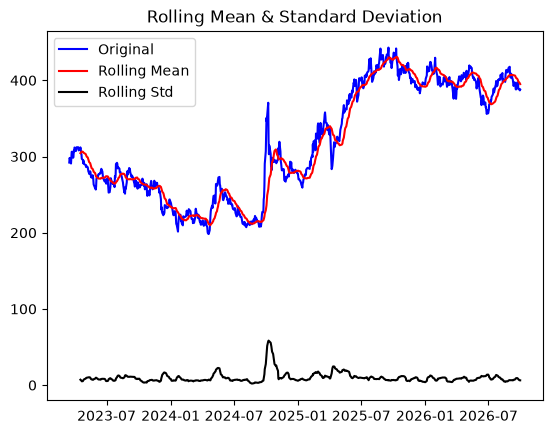

Results of Dickey-Fuller Test:
Test Statistic                  -1.039201
p-value                          0.738700
#Lags Used                       6.000000
Number of Observations Used    863.000000
Critical Value (1%)             -3.437950
Critical Value (5%)             -2.864895
Critical Value (10%)            -2.568556
dtype: float64


In [19]:
#... The following cells are use for model(s), such as LSTM in transformation
#... test stationarity with DFT

close_series = df['Close']
def test_stationarity(timeseries):
    '''
    Input: timeseries (dataframe): timeseries for which we want to study the stationarity
    '''
    
    #Determing rolling statistics
    rolmean = timeseries.rolling(20).mean()
    rolstd = timeseries.rolling(20).std()

    #Plot rolling statistics:
    orig = plt.plot(timeseries, color='blue',label='Original')
    mean = plt.plot(rolmean, color='red', label='Rolling Mean')
    std = plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean & Standard Deviation')
    plt.show(block=False)

    #Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value',\
                                             '#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)

test_stationarity(close_series)

<Figure size 640x480 with 0 Axes>

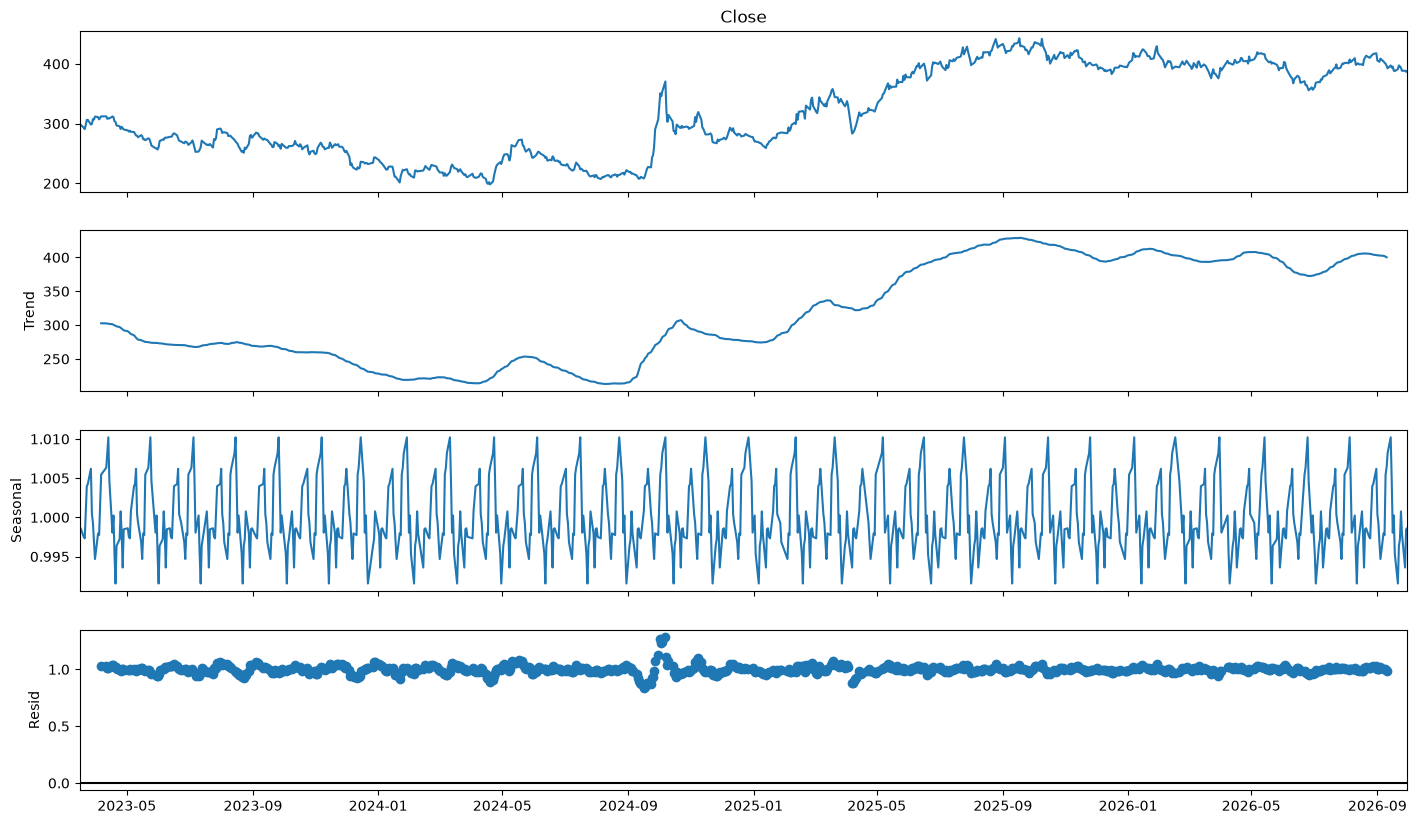

In [20]:
#from statsmodels.tsa.seasonal import seasonal_decompose

#To plot & view the trend and the seasonality
# here set the period to 28 as monthly average 

df_close = df['Close']
result = seasonal_decompose(df_close, model='multiplicative',period=28)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

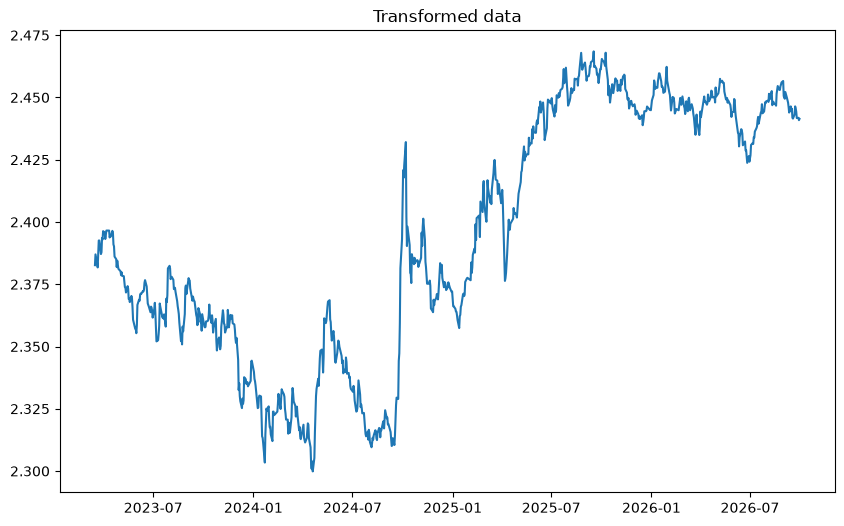

In [21]:
#... To apply log transform to reduce the trends effect while square root transform to flatten 

df_close_log = df_close.apply(np.log)
df_close_tf = df_close_log.apply(np.sqrt)

plt.figure(figsize = (10,6))
plt.plot(df_close_tf)
plt.title('Transformed data')

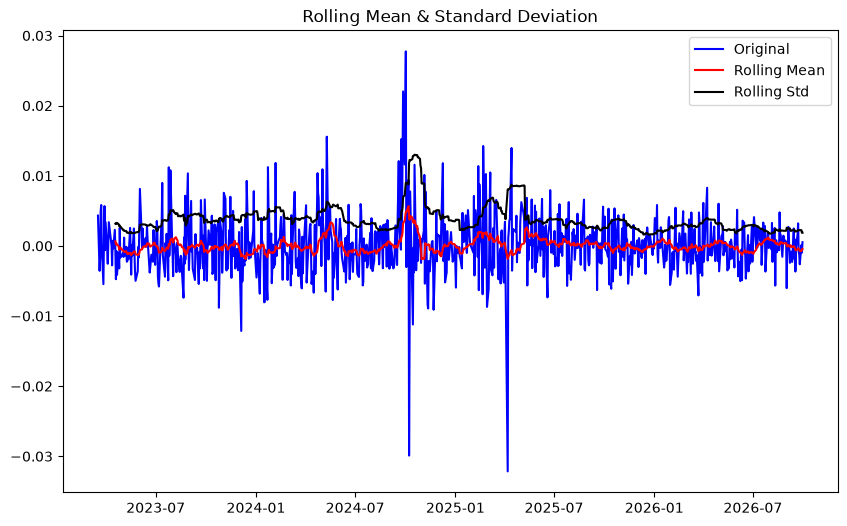

Results of Dickey-Fuller Test:
Test Statistic                -1.482818e+01
p-value                        1.917282e-27
#Lags Used                     2.000000e+00
Number of Observations Used    8.660000e+02
Critical Value (1%)           -3.437924e+00
Critical Value (5%)           -2.864883e+00
Critical Value (10%)          -2.568550e+00
dtype: float64


In [22]:
#... classical methold differenciating to handel with trand and seasonality
df_close_shift = df_close_tf - df_close_tf.shift()

df_close_shift.dropna(inplace=True)
plt.figure(figsize = (10,6))
test_stationarity(df_close_shift)

check p-value

In [23]:
#...MS LSTM
def preprocess_lstm(sequence, n_steps,n_features):
    X, y = list(), list()
    for i in range(len(sequence)):
        # find the end of this pattern
        end_ix = i + n_steps
        # check if we are beyond the sequence
        if end_ix >= len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
        X.append(seq_x)
        y.append(seq_y)
        
    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    return X, y

# choose the number of days on which to base our predictions 
#nb_days = 60
n_features = 1

X, y = preprocess_lstm(df_close_shift.to_numpy(), nb_days, n_features)

#Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]

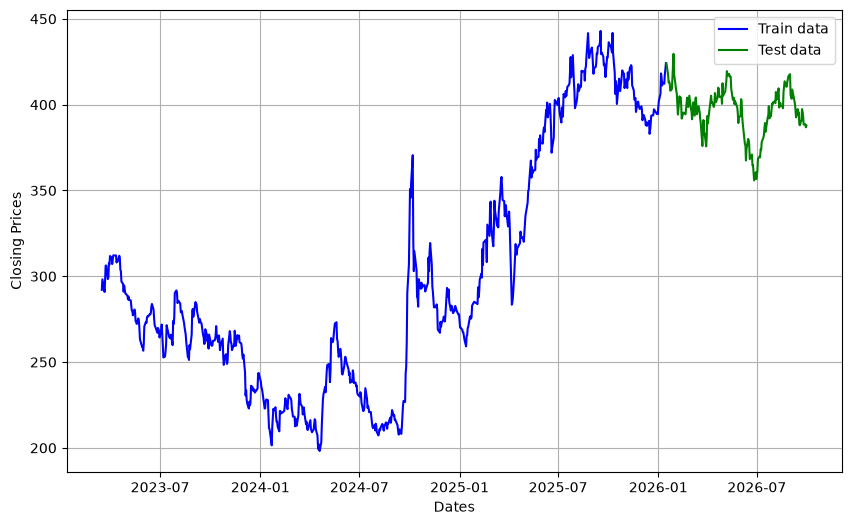

In [24]:
#... Split Data
train_original = df_close.iloc[:-test_days]
test_original = df_close.iloc[-test_days:]

plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.legend()

In [25]:
#... LSTM Vanilla LSTM
def vanilla_LSTM():
    model = Sequential()    
    model.add(LSTM(units=50, input_shape=(nb_days, n_features)))
    model.add(Dense(1))
    return model

#
model = vanilla_LSTM()
model.summary()
model.compile(optimizer='adam', 
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])    

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
#...Train and evaluate model
model.fit(X_train, 
          y_train, 
          epochs=epochsMS, 
          batch_size = batch_sizeMS)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 3.7501e-05 - mean_absolute_error: 0.0045
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 2.8167e-05 - mean_absolute_error: 0.0040
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 2.2506e-05 - mean_absolute_error: 0.0033
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 2.1954e-05 - mean_absolute_error: 0.0033
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 2.1758e-05 - mean_absolute_error: 0.0033
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.2794e-05 - mean_absolute_error: 0.0034
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 2.1326e-05 - mean_absolute_error: 0.0033
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 2.0970e-05 - mean_absolute_error: 0.0032
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 2.1346e-05 - mean_absolute_error: 0.0033
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 2.2731e-05 - mean_absolute_error: 0.0034

In [27]:
#...
# Evaluate the model on the test data using
print("Evaluate on test data")
results = model.evaluate(X_test, y_test, batch_size=32)
print("Test MSE:", results[0])
print("Test MAE:", results[1])

Evaluate on test data
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 7.0687e-06 - mean_absolute_error: 0.0021
Test MSE: 7.068655577313621e-06
Test MAE: 0.0020939114037901163


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


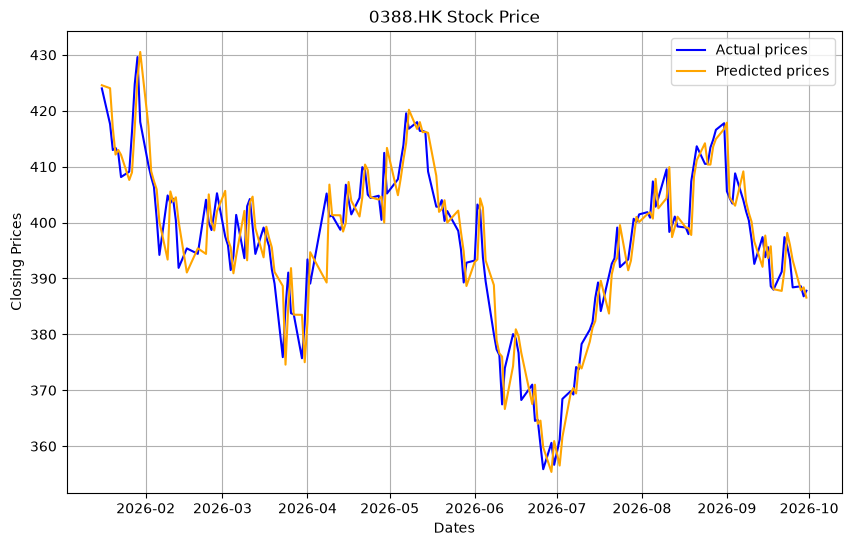

In [28]:
#...
# Prediction
y_pred = model.predict(X_test)

# We create a dataframe from y_pred to have date-time indexes.
pred_data = pd.DataFrame(y_pred[:,0], test_original.index,columns=['Close'])

# Apply inverse transformation from 1.d

# Add the differenciation term
pred_data['Close'] = pred_data['Close'] + df_close_tf.shift().values[-test_days:] 

# Take the square, and the exponent
pred_data = pred_data.apply(np.square)
pred_data = pred_data.apply(np.exp)

# Plot actual prices vs predicted prices 
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original,'b',label='Actual prices')
plt.plot(pred_data, 'orange',label='Predicted prices')
#plt.title(' Stock Price')
plt.title(company + ' Stock Price')

plt.legend()

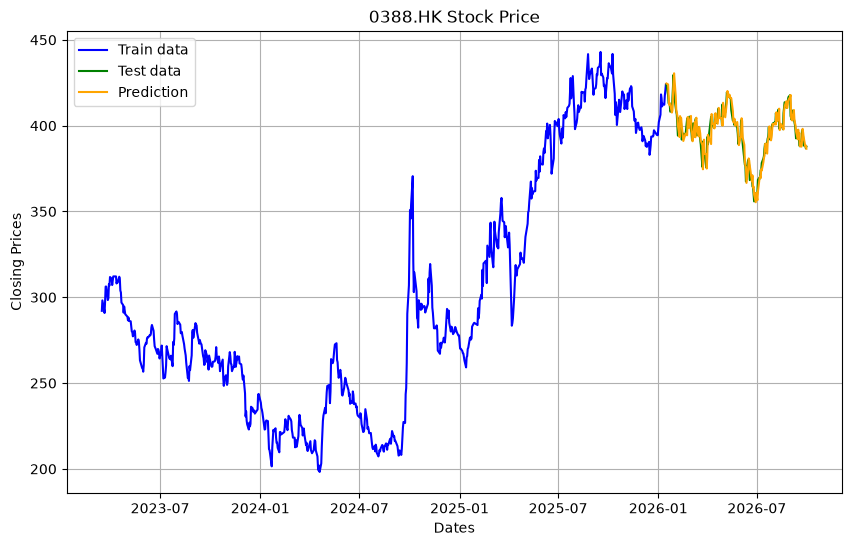

In [29]:
#...
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.plot(pred_data, 'orange', label='Prediction')
plt.title(company + ' Stock Price')
plt.legend()

In [30]:
#...Multiple-Step LSTM
def preprocess_multistep_lstm(sequence, n_steps_in, n_steps_out, features):
    X, y = list(), list()
    for i in range(len(sequence)):
        # find the end of this pattern
        end_ix = i + n_steps_in
        out_end_ix = end_ix + n_steps_out
        # check if we are beyond the sequence
        if out_end_ix > len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
        X.append(seq_x)
        y.append(seq_y)

    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    
    return X, y

# Number of days into the future we want to predict
#n_steps_out = 30

# choose the number of days on which to base our predictions 
#nb_days = 60

n_features = 1

X, y = preprocess_multistep_lstm(df_close_shift.to_numpy(), nb_days, n_steps_out, n_features)

#
#Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]

In [31]:
#...
def vanilla_multistep_LSTM():
    model = Sequential()    
    model.add(LSTM(units=50, input_shape=(nb_days, n_features)))
    model.add(Dense(n_steps_out))
    return model

#
model = vanilla_multistep_LSTM()
model.summary()
model.compile(optimizer='adam', 
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,910 (42.62 KB)

 Trainable params: 10,910 (42.62 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
#...
model.fit(X_train, 
          y_train, 
          epochs=epochsMS, 
          batch_size = batch_sizeMS)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 2.3960e-05 - mean_absolute_error: 0.0035
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 2.1942e-05 - mean_absolute_error: 0.0033
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 2.2287e-05 - mean_absolute_error: 0.0033
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 2.1730e-05 - mean_absolute_error: 0.0033
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 2.1651e-05 - mean_absolute_error: 0.0033
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 2.2025e-05 - mean_absolute_error: 0.0033
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 2.1970e-05 - mean_absolute_error: 0.0033
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 2.1614e-05 - mean_absolute_error: 0.0033
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 2.1570e-05 - mean_absolute_error: 0.0033
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 2.1713e-05 - mean_absolute_error: 0.0033

In [33]:
#...
# Evaluate the model on the test set
print("Evaluate on test data")
results = model.evaluate(X_test, y_test, batch_size=32)

print("Test MSE:", results[0])
print("Test MAE:", results[1])

Evaluate on test data
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 7.3718e-06 - mean_absolute_error: 0.0022
Test MSE: 7.371756510110572e-06
Test MAE: 0.00215354491956532


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step


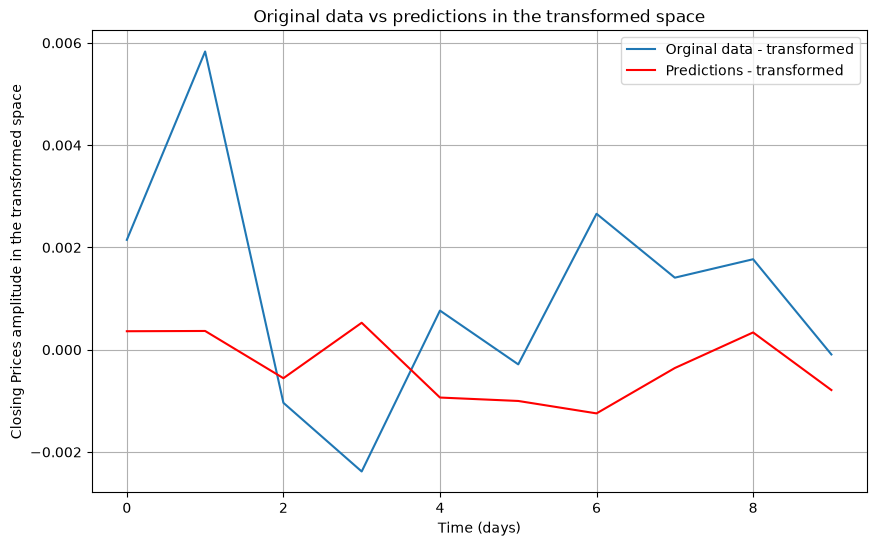

In [34]:
#...
# Prediction
y_pred = model.predict(X_test)

# the_day is the day from which we will study the n_steps_out-th dayS of prediction into 
# the future. Note: The first day start at index 0
the_day = 0
y_pred_days = y_pred[the_day,:]

plt.figure(figsize=(10,6))
plt.grid(True)
plt.plot(y_test[the_day,:],label='Orginal data - transformed')
plt.plot(y_pred_days, color='red',label='Predictions - transformed')
plt.xlabel('Time (days)')
plt.ylabel('Closing Prices amplitude in the transformed space')
plt.title('Original data vs predictions in the transformed space')
plt.legend()

In [35]:
#...
# Apply inverse transformations from 3.a

# Add the differenciation term
pred_diff_cumsum = y_pred_days.cumsum()

base_number = df_close_tf.values[-test_days+the_day+nb_days-1]
idx = test_original.iloc[the_day:the_day+n_steps_out].index

pred_tf = pd.Series(base_number, index=idx)
pred_tf = pred_tf.add(pred_diff_cumsum,fill_value=0)

print(pred_tf)

Date
2026-01-16    2.446029
2026-01-19    2.446396
2026-01-20    2.445839
2026-01-21    2.446366
2026-01-22    2.445430
2026-01-23    2.444428
2026-01-26    2.443183
2026-01-27    2.442825
2026-01-28    2.443163
2026-01-29    2.442374
dtype: float64


In [36]:
#...
# Take the square, and the exponent
pred_log = pred_tf.apply(np.square)
pred = pred_log.apply(np.exp)
print(pred)

Date
2026-01-16    396.651386
2026-01-19    397.363343
2026-01-20    396.282062
2026-01-21    397.305298
2026-01-22    395.491852
2026-01-23    393.558591
2026-01-26    391.170756
2026-01-27    390.486907
2026-01-28    391.131965
2026-01-29    389.627829
dtype: float64


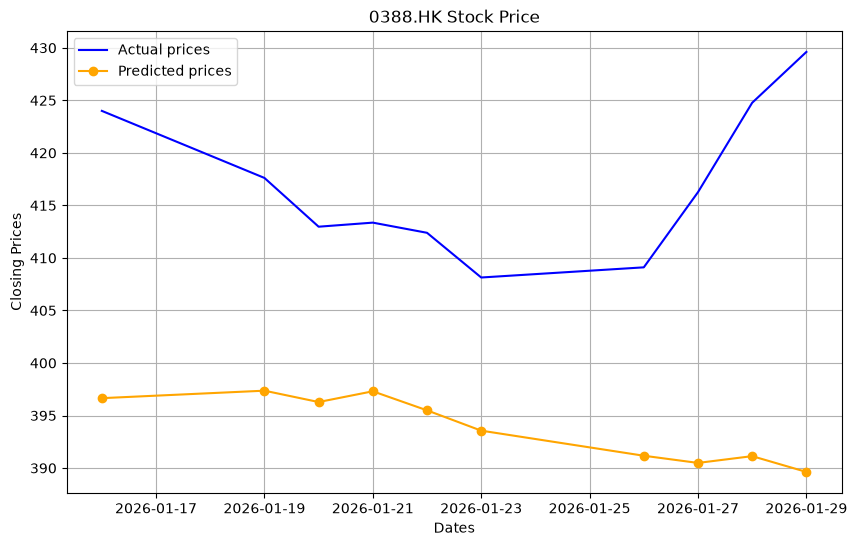

In [37]:
#...
# Plot actual prices vs predicted prices 
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original.iloc[max(0,the_day-30):the_day+n_steps_out],'b',label='Actual prices')
plt.plot(pred, '-o',color='orange',label='Predicted prices')
plt.title(company + ' Stock Price')

plt.legend()

In [38]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
from sklearn.metrics import r2_score
import statsmodels.api as sm

# 1. Extract the exact actual prices that align with the prediction period
# Based on your plot, 'pred' starts at 'the_day' and goes forward for 'n_steps_out' steps.
actual_for_pred_period = test_original.iloc[the_day : the_day + n_steps_out]

# 2. Ensure both are flattened 1D arrays/Series with no missing values
y_true = actual_for_pred_period.values.flatten()
y_pred = pred.flatten() if hasattr(pred, 'flatten') else pred

X = sm.add_constant(y_true)

#fit linear regression model
model = sm.OLS(y_pred, X).fit()

#view model summary
summary = model.summary()
print(summary)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.081
Model:                            OLS   Adj. R-squared:                 -0.034
Method:                 Least Squares   F-statistic:                    0.7068
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.425
Time:                        20:19:24   Log-Likelihood:                -24.437
No. Observations:                  10   AIC:                             52.87
Df Residuals:                       8   BIC:                             53.48
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        444.7763     60.515      7.350      0.0

In [41]:
#import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate Metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)  # Alternative: mean_squared_error(y_true, y_pred, squared=False)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Directional Accuracy (Crucial for price trends)
# Compares if the predicted direction (up/down) matches the actual direction
actual_direction = np.diff(y_true) > 0
predicted_direction = np.diff(y_pred) > 0
directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

# 4. Print Evaluation Results
print("--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Pct Error (MAPE): {mape:.2f}%")
print(f"Directional Accuracy (DA):      {directional_accuracy:.2f}%")


--- Model Evaluation Metrics ---
Mean Absolute Error (MAE):      22.9148
Mean Squared Error (MSE):       590.8331
Root Mean Squared Error (RMSE): 24.3071
Mean Absolute Pct Error (MAPE): 5.47%
Directional Accuracy (DA):      55.56%


In [219]:
# Follow from ADF Test if series is stationary
scaler = MinMaxScaler()
df['Close'] = scaler.fit_transform(df[['Close']])

In [220]:
# Train and Verify Split (80:20 Ratio)
#from sklearn.model_selection import train_test_split

def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back):
        dataX.append(dataset[i:(i + look_back)])
        dataY.append(dataset[i + look_back])
    return np.array(dataX), np.array(dataY)

close_values = df['Close'].values 

X, Y = create_dataset(close_values, look_back=30)

trainX, testX, trainY, testY = train_test_split(X, Y, test_size=0.2, shuffle=False)


In [221]:
# Data for LSTM 
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [215]:
#1 LSTM ***SKIP
model = Sequential()
model.add(LSTM(units=50, input_shape=(30, 1)))
model.add(Dense(units=1))
model.compile(loss='mean_squared_error', optimizer='adam')
model.summary()
model.fit(trainX, trainY, epochs=epochs2, batch_size=batch_size2)

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_18 (LSTM)                       │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0331
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0046
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0020
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 9.7706e-04
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 7.9453e-04
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 7.5218e-04
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 7.1665e-04
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 6.9815e-04
Epoch 9/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 6.9846e-04
Epoch 10/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 6.6905e-04
Epoch 11/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 6.6121e-04
Epoch 12/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 6.5218e-04
Epoch 13/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 6.2959e-04
Epoch 14/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 6.5598e-04
Epoch 15/30
17/17 ━━━━━━━━━

#
LSTM(50 units) → Captures long-term dependencies

Dropout(0.2) → Prevents overfitting

Dense Layers → Produces final prediction

In [222]:
#2 LSTM
#from tensorflow.keras.models import Sequential  
#from tensorflow.keras.layers import LSTM, Dense, Dropout  

model = Sequential([  
    LSTM(units=50, return_sequences=True, input_shape=(trainX.shape[1], 1)),  
    Dropout(0.2),  
    LSTM(units=50, return_sequences=False),  
    Dropout(0.2),  
    Dense(units=25),  
    Dense(units=1)  
])  

model.compile(optimizer='adam', loss='mean_squared_error')

model.fit(trainX, trainY, epochs=epochs2, batch_size=batch_size2)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0173
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0037
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0018
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0016
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0014
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0013
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0013
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0013
Epoch 9/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0012
Epoch 10/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0012
Epoch 11/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0012
Epoch 12/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0012
Epoch 13/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0011
Epoch 14/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0012
Epoch 15/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0011
Epoc

In [223]:
# Prediction & Result
testPredict = model.predict(testX)
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform(testY.reshape(-1, 1))

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step


In [224]:
#from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(testY, testPredict))
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 0.04314230267751027


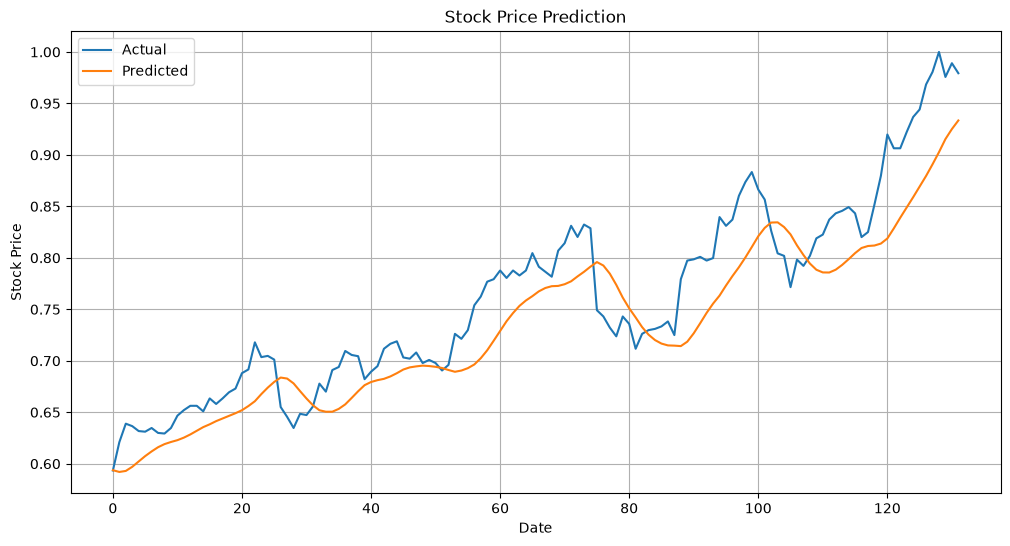

In [225]:
#2
plt.figure(figsize=(12, 6))
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.title("Stock Price Prediction")
plt.plot(testY, label='Actual')
plt.plot(testPredict, label='Predicted')
plt.grid(True)
plt.legend()
plt.show()

For this study, we will focus on the closing price, as it represents the final market sentiment for each trading day.